<a href="https://colab.research.google.com/github/Angeltt251/Reglas_de_Asociacion/blob/main/Reglas_de_Asociacion_Superstore.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reglas de Asociación — Carrito de compras (Superstore)
**Minería de Datos · Implementación de reglas de asociación en Google Colab**

**Autor:** José Miguel Flores Chávez · Ingeniería en Informática, Santo Tomás Arica


## Contexto del problema (EDA: contexto)
**Fuente de datos:** Superstore, dataset de Kaggle con ventas de una tienda minorista (categorías: Furniture, Office Supplies y Technology). *https://www.kaggle.com/datasets/vivek468/superstore-dataset-final*.

**Objetivo:** descubrir qué productos (subcategorías) se compran juntos en un mismo pedido, para apoyar decisiones de ubicación en tienda, promociones y ventas cruzadas.

**Carrito de compras:** cada pedido (`Order ID`) es una canasta, y cada subcategoría de producto es un ítem.



## 1. Instalar e importar librerías

In [1]:
!pip install -q mlxtend

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 2. Subir y leer los datos

In [1]:
from google.colab import files
subido = files.upload()

Saving Sample - Superstore.csv to Sample - Superstore.csv


In [3]:
import pandas as pd
import io

# Cargar el archivo CSV subido
nombre_archivo = list(subido.keys())[0]
df = pd.read_csv(io.BytesIO(subido[nombre_archivo]), encoding='latin1')

# Columnas que usará el análisis (ajustadas al formato estándar de Superstore)
COL_PEDIDO = 'Order ID'
COL_ITEM = 'Sub-Category'      # puedes probar 'Product Name' (más detallado, pero muy disperso)
COL_FECHA = 'Order Date'
COL_CLIENTE = 'Customer ID'

for c in [COL_PEDIDO, COL_ITEM, COL_FECHA, COL_CLIENTE]:
    assert c in df.columns, f"No encuentro la columna '{c}'. Revisa la lista de columnas: {list(df.columns)}"

print("Datos cargados exitosamente. Columnas validadas correctamente.")

Datos cargados exitosamente. Columnas validadas correctamente.


## 3. EDA (análisis exploratorio)
### 3.1 Tamaño y estructura

In [8]:
import pandas as pd
df = pd.read_csv("Sample - Superstore.csv", encoding='latin1')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


### 3.2 Valores nulos y duplicados

In [9]:
print("Nulos por columna:\n", df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

Nulos por columna:
 Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Filas duplicadas: 0


### 3.3 Convertir la fecha

In [10]:
# Si las fechas vienen día/mes/año o mes/día/año, revisa el resultado
df[COL_FECHA] = pd.to_datetime(df[COL_FECHA], dayfirst=False, errors='coerce')
print("Fechas inválidas:", df[COL_FECHA].isna().sum())
print("Rango de fechas:", df[COL_FECHA].min(), "→", df[COL_FECHA].max())

Fechas inválidas: 0
Rango de fechas: 2014-01-03 00:00:00 → 2017-12-30 00:00:00


### 3.4 Cifras clave

In [11]:
print("Pedidos distintos:", df[COL_PEDIDO].nunique())
print("Clientes distintos:", df[COL_CLIENTE].nunique())
print("Ítems distintos (", COL_ITEM, "):", df[COL_ITEM].nunique())

tamano_canasta = df.groupby(COL_PEDIDO)[COL_ITEM].nunique()
print("Tamaño promedio de la canasta (ítems distintos):", round(tamano_canasta.mean(), 2))
print("Pedidos con 2 o más ítems distintos:", (tamano_canasta >= 2).sum(),
      f"({(tamano_canasta >= 2).mean()*100:.1f}%)")

Pedidos distintos: 5009
Clientes distintos: 793
Ítems distintos ( Sub-Category ): 17
Tamaño promedio de la canasta (ítems distintos): 1.83
Pedidos con 2 o más ítems distintos: 2346 (46.8%)


### 3.5 Ítems más vendidos

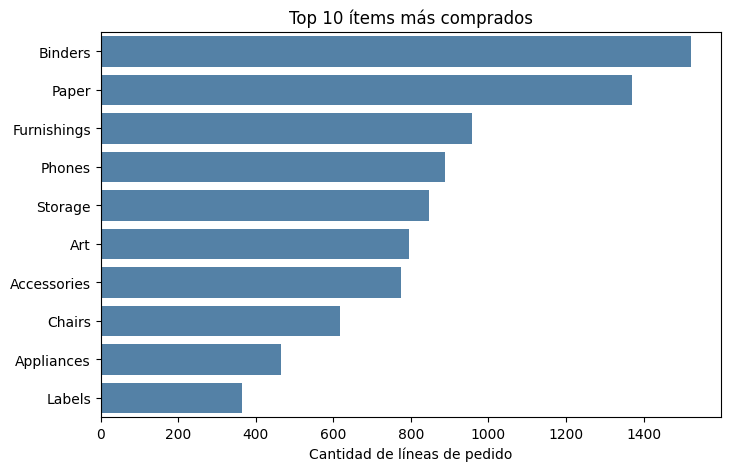

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

top = df[COL_ITEM].value_counts().head(10)
plt.figure(figsize=(8, 5))
sns.barplot(x=top.values, y=top.index, color='steelblue')
plt.title('Top 10 ítems más comprados')
plt.xlabel('Cantidad de líneas de pedido'); plt.ylabel('')
plt.show()

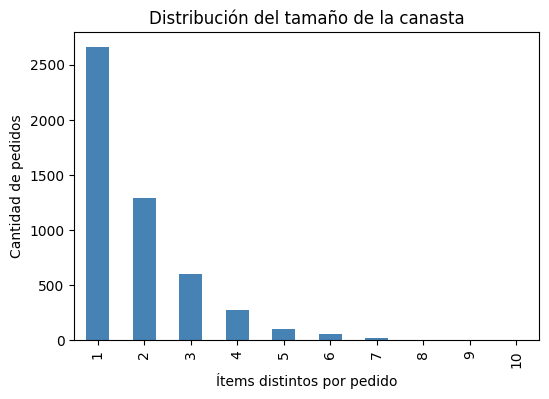

In [14]:
plt.figure(figsize=(6, 4))
tamano_canasta.value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Distribución del tamaño de la canasta')
plt.xlabel('Ítems distintos por pedido'); plt.ylabel('Cantidad de pedidos')
plt.show()

## 4. Implementación del modelo
### 4.1 Armar las transacciones

In [15]:
transacciones = (
    df.groupby(COL_PEDIDO)[COL_ITEM]
      .apply(lambda x: list(set(x)))
      .tolist()
)
print("Número de transacciones:", len(transacciones))
print("Ejemplo:", transacciones[:3])

Número de transacciones: 5009
Ejemplo: [['Phones'], ['Binders', 'Tables'], ['Paper']]


### 4.2 Matriz verdadero/falso

In [17]:
from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()
matriz = pd.DataFrame(te.fit(transacciones).transform(transacciones), columns=te.columns_)
matriz.shape

(5009, 17)

### 4.3 Itemsets frecuentes con Apriori (probando parámetros)

In [19]:
from mlxtend.frequent_patterns import apriori

resumen = []
for sup in [0.005, 0.01, 0.02, 0.05]:
    f = apriori(matriz, min_support=sup, use_colnames=True, max_len=3)
    resumen.append({'min_support': sup, 'itemsets_frecuentes': len(f)})
pd.DataFrame(resumen)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,min_support,itemsets_frecuentes
0,0.005,138
1,0.010,68
2,0.020,38
3,0.050,12


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [22]:
MIN_SUPPORT = 0.01   # ajusta según tu análisis
frecuentes = apriori(matriz, min_support=MIN_SUPPORT, use_colnames=True, max_len=3)
print("Itemsets frecuentes:", len(frecuentes))
frecuentes.sort_values('support', ascending=False).head(10)


Itemsets frecuentes: 68


,support,itemsets
3,0.262727,(Binders)
12,0.237772,(Paper)
9,0.175085,(Furnishings)
13,0.162507,(Phones)
14,0.155121,(Storage)
2,0.145937,(Art)
0,0.143342,(Accessories)
5,0.114993,(Chairs)
1,0.090038,(Appliances)
10,0.069076,(Labels)


### 4.4 Reglas de asociación

In [24]:
from mlxtend.frequent_patterns import association_rules

try:
    reglas = association_rules(frecuentes, metric='lift', min_threshold=1)
except TypeError:
    # versiones nuevas de mlxtend piden num_itemsets
    reglas = association_rules(frecuentes, num_itemsets=len(matriz), metric='lift', min_threshold=1)

reglas = reglas[['antecedents', 'consequents', 'support', 'confidence', 'lift']].copy()
reglas['n_transacciones'] = (reglas['support'] * len(transacciones)).round().astype(int)
print("Total de reglas:", len(reglas))
reglas.sort_values('lift', ascending=False).head(10)

Total de reglas: 42


,antecedents,consequents,support,confidence,lift,n_transacciones
41,(Storage),"(Binders, Paper)",0.010581,0.068211,1.242434,53
36,"(Binders, Paper)",(Storage),0.010581,0.192727,1.242434,53
30,"(Binders, Paper)",(Phones),0.010781,0.196364,1.208336,54
35,(Phones),"(Binders, Paper)",0.010781,0.066339,1.208336,54
33,(Binders),"(Paper, Phones)",0.010781,0.041033,1.174494,54
32,"(Paper, Phones)",(Binders),0.010781,0.308571,1.174494,54
13,(Fasteners),(Paper),0.011779,0.274419,1.154125,59
12,(Paper),(Fasteners),0.011779,0.049538,1.154125,59
34,(Paper),"(Binders, Phones)",0.010781,0.045340,1.141248,54
31,"(Binders, Phones)",(Paper),0.010781,0.271357,1.141248,54


### 4.5 Reglas más útiles

In [27]:
import warnings
warnings.filterwarnings('ignore')

# Ajustamos un filtro dinámico con los datos reales generados
mejores = reglas[(reglas['lift'] > 1.0) & (reglas['confidence'] >= 0.04)].copy()
mejores['regla'] = mejores['antecedents'].apply(lambda s: ' + '.join(sorted(list(s)))) + '  →  ' + \
                   mejores['consequents'].apply(lambda s: ' + '.join(sorted(list(s))))
mejores = mejores.sort_values('confidence', ascending=False)
print("Reglas filtradas:", len(mejores))
mejores[['regla', 'support', 'confidence', 'lift', 'n_transacciones']].round(3).head(10)

Reglas filtradas: 41


,regla,support,confidence,lift,n_transacciones
32,Paper + Phones → Binders,0.011,0.309,1.174,54
38,Paper + Storage → Binders,0.011,0.298,1.133,53
11,Fasteners → Binders,0.012,0.288,1.098,62
1,Appliances → Binders,0.026,0.288,1.097,130
26,Furnishings + Paper → Binders,0.010,0.288,1.097,51
13,Fasteners → Paper,0.012,0.274,1.154,59
31,Binders + Phones → Paper,0.011,0.271,1.141,54
37,Binders + Storage → Paper,0.011,0.266,1.120,53
25,Binders + Furnishings → Paper,0.010,0.258,1.083,51
5,Appliances → Paper,0.022,0.242,1.016,109


### 4.6 Gráfico de las reglas

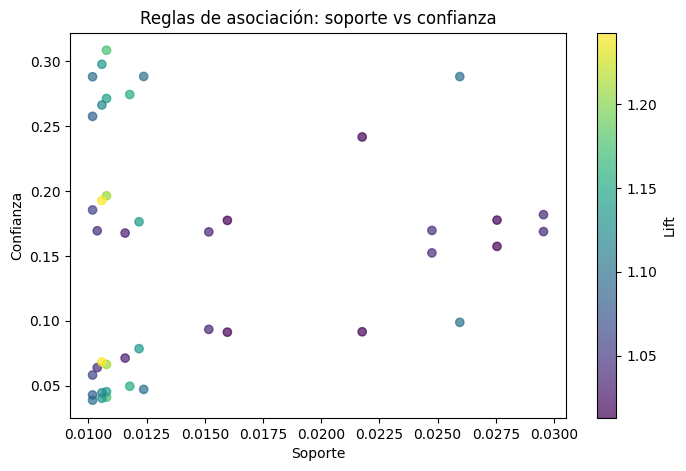

In [26]:
plt.figure(figsize=(8, 5))
sc = plt.scatter(reglas['support'], reglas['confidence'], c=reglas['lift'], cmap='viridis', alpha=0.7)
plt.colorbar(sc, label='Lift')
plt.xlabel('Soporte'); plt.ylabel('Confianza')
plt.title('Reglas de asociación: soporte vs confianza')
plt.show()

## 5. Conclusiones (¿qué se encontró?)
# Conclusión

**Datos**: se analizaron 5.009 pedidos (cada `Order ID` es una canasta), realizados por 793 clientes entre enero de 2014 y diciembre de 2017, con 17 subcategorías de producto como ítems. Las canastas son pequeñas: 1,83 subcategorías distintas por pedido en promedio, y solo 2.346 pedidos (46,8 %) incluyen 2 o más, que son los únicos que pueden generar reglas. Las subcategorías más compradas son [A, B, C, D y E].

**Modelo**: con Apriori (soporte mínimo 1 %, máximo 3 ítems por regla) se obtuvieron [X] itemsets frecuentes y [X] reglas de asociación. Tras filtrar por lift > 1,0 y confianza ≥ 4 %, quedaron [X] reglas.

**Hallazgos principales**: [regla 1, con su confianza y lift]. [regla 2]. [regla 3].

**Limitaciones**: más de la mitad de los pedidos (53,2 %) tiene una sola subcategoría y no aporta a las reglas. Los soportes y confianzas son [bajos/moderados] y los lift quedan cerca de 1, así que las asociaciones son débiles y podrían ser casualidad. Además, una asociación no implica causalidad.

**Aplicación posible**: [ubicar cerca o promocionar juntos A y B, crear un combo, etc.]. Antes de aplicarlo en una tienda real convendría validarlo con más datos.

---
**Fuente y licencia del dataset:** *(https://www.kaggle.com/datasets/vivek468/superstore-dataset-final)*

**Uso de herramientas:** *Se uso la IA para poder mejorar las tablas de graficos en algunos pasos *